1. XOR 문제 시각화 창을 확인하세요.


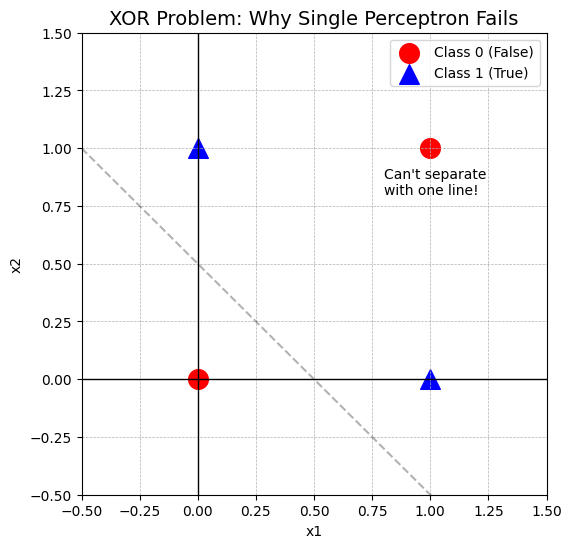

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1단계: XOR 데이터 정의 및 문제 상황 시각화
# ---------------------------------------------------------
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([0, 1, 1, 0])

def plot_xor_problem(X, y):
    plt.figure(figsize=(6, 6))
    plt.title("XOR Problem: Why Single Perceptron Fails", fontsize=14)

    # 0인 데이터 (Circle), 1인 데이터 (Triangle) 산점도
    plt.scatter(X[y==0][:, 0], X[y==0][:, 1], s=200, c='red', marker='o', label='Class 0 (False)')
    plt.scatter(X[y==1][:, 0], X[y==1][:, 1], s=200, c='blue', marker='^', label='Class 1 (True)')

    # 격자 및 축 설정
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.axhline(y=0, color='k', linewidth=1)
    plt.axvline(x=0, color='k', linewidth=1)
    plt.xlim(-0.5, 1.5)
    plt.ylim(-0.5, 1.5)
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.legend()

    # 설명: 직선 하나로 빨간점과 파란점을 나눌 수 없음을 시각적으로 보여줌
    # 가상의 직선(실패 예시)을 점선으로 그리기
    x_line = np.linspace(-0.5, 1.5, 10)
    plt.plot(x_line, -x_line + 0.5, 'k--', alpha=0.3, label='Linear Boundary (Fail)')
    plt.text(0.8, 0.8, "Can't separate\nwith one line!", color='black', fontsize=10)

    plt.show()

print("1. XOR 문제 시각화 창을 확인하세요.")
plot_xor_problem(X, y)

In [2]:
def sigmoid(x):
  return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
  return x * (1 - x)

In [3]:
np.random.seed(42)
W1 = np.random.uniform(size=(2,4))
b1 = np.random.uniform(size=(1,4))
W2 = np.random.uniform(size=(4,1))
b2 = np.random.uniform(size=(1,1))

l_r = 0.1
epochs = 10000

y_reshaped = y.reshape(-1,1)

In [6]:
loss_history = []

for epoch in range(epochs):
  hidden_input = np.dot(X, W1) + b1
  hidden_output = sigmoid(hidden_input)
  final_input = np.dot(hidden_output, W2) + b2
  pred = sigmoid(final_input)

  error = y_reshaped - pred
  d_pred = error * sigmoid_derivative(pred)
  error_hidden = d_pred.dot(W2.T)
  d_hidden = error_hidden * sigmoid_derivative(hidden_output)

  W2 += hidden_output.T.dot(d_pred) * l_r
  b2 += np.sum(d_pred, axis =0, keepdims=True) * l_r
  W1 += X.T.dot(d_hidden) * l_r
  b1 += np.sum(d_hidden, axis=0, keepdims=True) * l_r

  if epoch % 1000 == 0:
    loss = np.mean(np.square(error))
    loss_history.append(loss)

print("\n2. 학습 완료. 최종 Loss:", loss_history[-1])


2. 학습 완료. 최종 Loss: 0.0048623553009466015


3. 학습된 결정 경계 시각화 창을 확인하세요.


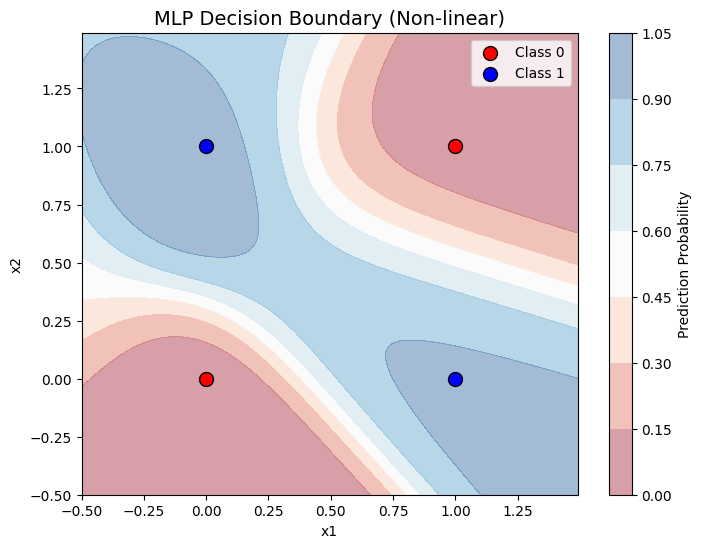

In [7]:
def plot_decision_boundary(X, y, W1, b1, W2, b2):
    plt.figure(figsize=(8, 6))

    # 1. 배경에 등고선(Contour) 그리기 - 모델의 예측값 분포
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                         np.arange(y_min, y_max, 0.01))

    # Meshgrid의 모든 점에 대해 예측 수행
    grid_points = np.c_[xx.ravel(), yy.ravel()]
    h_out = sigmoid(np.dot(grid_points, W1) + b1)
    Z = sigmoid(np.dot(h_out, W2) + b2)
    Z = Z.reshape(xx.shape)

    # 등고선 플롯 (영역 채우기)
    plt.contourf(xx, yy, Z, alpha=0.4, cmap=plt.cm.RdBu)
    plt.colorbar(label='Prediction Probability')

    # 2. 원래 데이터 포인트 찍기
    plt.scatter(X[y==0][:, 0], X[y==0][:, 1], s=100, c='red', edgecolors='k', label='Class 0')
    plt.scatter(X[y==1][:, 0], X[y==1][:, 1], s=100, c='blue', edgecolors='k', label='Class 1')

    plt.title("MLP Decision Boundary (Non-linear)", fontsize=14)
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.legend()
    plt.show()

print("3. 학습된 결정 경계 시각화 창을 확인하세요.")
plot_decision_boundary(X, y, W1, b1, W2, b2)

In [8]:
##순전파와 역전파 확인하기

import numpy as np

# 1. 시그모이드 및 미분 함수
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    return x * (1 - x)

# 2. 데이터 정의 (XOR)
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]]) # Shape: (4, 2)
y = np.array([[0], [1], [1], [0]])             # Shape: (4, 1)

# 3. 가중치 초기화 (추적을 위해 고정된 값 사용 또는 랜덤)
np.random.seed(42)
W1 = np.random.uniform(size=(2, 2))  # Input(2) -> Hidden(2)
b1 = np.random.uniform(size=(1, 2))
W2 = np.random.uniform(size=(2, 1))  # Hidden(2) -> Output(1)
b2 = np.random.uniform(size=(1, 1))

learning_rate = 0.1

print("========== [1] 초기 설정 (Initialization) ==========")
print(f"입력 데이터 X Shape: {X.shape}")
print(f"정답 레이블 y Shape: {y.shape}")
print(f"W1 (Input->Hidden) Shape: {W1.shape}")
print(f"W2 (Hidden->Output) Shape: {W2.shape}")
print("-" * 50)

# --- 순전파 (Forward Propagation) ---
print("\n========== [2] 순전파 (Forward Pass) ==========")

# [Hidden Layer]
# 선형 계산: Z1 = X @ W1 + b1
z1 = np.dot(X, W1) + b1
print(f"1. 은닉층 선형 합 (Z1) Shape: {z1.shape}")
print(f"   => 값 예시(첫 행): {z1[0]}")

# 활성화: A1 = sigmoid(Z1)
a1 = sigmoid(z1)
print(f"2. 은닉층 활성화 출력 (A1) Shape: {a1.shape}")
print(f"   => 값 예시(첫 행 - 비선형 변환됨): {a1[0]}")

# [Output Layer]
# 선형 계산: Z2 = A1 @ W2 + b2
z2 = np.dot(a1, W2) + b2
print(f"3. 출력층 선형 합 (Z2) Shape: {z2.shape}")

# 활성화: A2 = sigmoid(Z2) (최종 예측값)
a2 = sigmoid(z2)
print(f"4. 최종 예측값 (A2) Shape: {a2.shape}")
print(f"   => 예측 결과:\n{a2.flatten()}")


# --- 역전파 (Backward Propagation) ---
print("\n========== [3] 역전파 (Backward Pass) ==========")

# 1. 오차 계산
error = y - a2
print(f"1. 오차 (Target - Output) Shape: {error.shape}")

# 2. 출력층 기울기 (Gradient) 계산: Chain Rule
# d_output = Error * sigmoid_derivative(Output)
# 오차가 클수록, 그리고 활성화 함수의 미분값이 클수록 기울기가 큼
d_output = error * sigmoid_derivative(a2)
print(f"2. 출력층의 델타 (d_output) Shape: {d_output.shape}")

# 3. 은닉층으로 오차 전파
# 출력층 델타와 W2를 내적하여 은닉층 쪽으로 에러를 보냄
error_hidden = d_output.dot(W2.T)
print(f"3. 은닉층으로 전달된 오차 (Error_Hidden) Shape: {error_hidden.shape}")
print("   => (4x1) dot (1x2) -> (4x2)")

# 4. 은닉층 기울기 계산
# d_hidden = 전달된_오차 * sigmoid_derivative(Hidden_Output)
d_hidden = error_hidden * sigmoid_derivative(a1)
print(f"4. 은닉층의 델타 (d_hidden) Shape: {d_hidden.shape}")


# --- 가중치 업데이트 (Weight Update) ---
print("\n========== [4] 가중치 업데이트 (Update) ==========")

# W2 업데이트량 계산: Hidden_Output_Transposed * d_output
# (2x4) dot (4x1) -> (2x1) : 가중치 W2와 같은 모양이 됨
w2_update = a1.T.dot(d_output) * learning_rate
W2 += w2_update
print(f"W2 업데이트 완료. Shape 변화 없음: {W2.shape}")

# W1 업데이트량 계산: Input_Transposed * d_hidden
# (2x4) dot (4x2) -> (2x2) : 가중치 W1과 같은 모양이 됨
w1_update = X.T.dot(d_hidden) * learning_rate
W1 += w1_update
print(f"W1 업데이트 완료. Shape 변화 없음: {W1.shape}")

print("\n========== [5] 1 Epoch 종료 ==========")

========== [1] 초기 설정 (Initialization) ==========
입력 데이터 X Shape: (4, 2)
정답 레이블 y Shape: (4, 1)
W1 (Input->Hidden) Shape: (2, 2)
W2 (Hidden->Output) Shape: (2, 1)
--------------------------------------------------

========== [2] 순전파 (Forward Pass) ==========
1. 은닉층 선형 합 (Z1) Shape: (4, 2)
   => 값 예시(첫 행): [0.15601864 0.15599452]
2. 은닉층 활성화 출력 (A1) Shape: (4, 2)
   => 값 예시(첫 행 - 비선형 변환됨): [0.53892573 0.53891974]
3. 출력층 선형 합 (Z2) Shape: (4, 1)
4. 최종 예측값 (A2) Shape: (4, 1)
   => 예측 결과:
[0.7501134  0.7740691  0.78391515 0.79889097]

========== [3] 역전파 (Backward Pass) ==========
1. 오차 (Target - Output) Shape: (4, 1)
2. 출력층의 델타 (d_output) Shape: (4, 1)
3. 은닉층으로 전달된 오차 (Error_Hidden) Shape: (4, 2)
   => (4x1) dot (1x2) -> (4x2)
4. 은닉층의 델타 (d_hidden) Shape: (4, 2)

========== [4] 가중치 업데이트 (Update) ==========
W2 업데이트 완료. Shape 변화 없음: (2, 1)
W1 업데이트 완료. Shape 변화 없음: (2, 2)

========== [5] 1 Epoch 종료 ==========


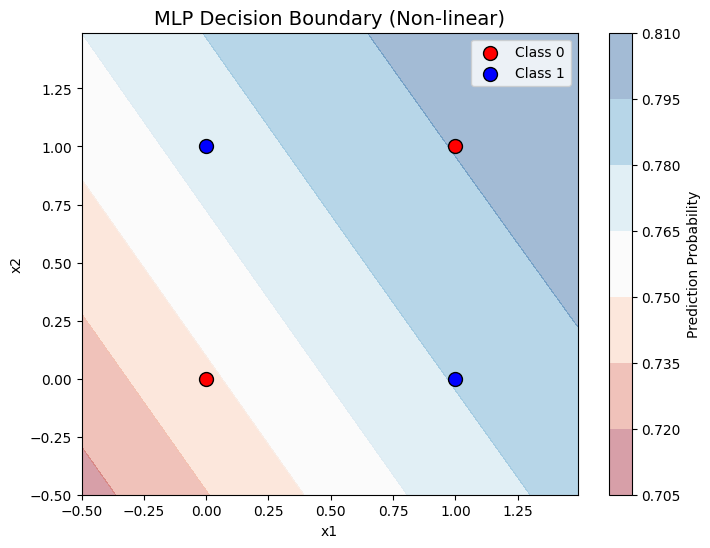

In [10]:
plot_decision_boundary(X, y.flatten(), W1, b1, W2, b2)